In [1]:

# ============================================
# AMAZON SALES INTELLIGENCE & ORDER PREDICTION
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================

# Data manipulation and numerical computation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Reproducibility
RANDOM_STATE = 42

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


All libraries imported successfully!
Pandas version: 2.3.3
NumPy version: 2.4.3


In [8]:
from pathlib import Path

DATASET_NAME = "amazon_sales_50000_ml_dataset.csv"
data_candidates = [
    Path.cwd() / "data" / DATASET_NAME,
    Path.cwd().parent / "data" / DATASET_NAME,
]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        f"{DATASET_NAME} was not found under the project data folder."
    )
PROJECT_DIR = data_path.parent.parent

df = pd.read_csv(data_path)
print("Dataset loaded successfully!")
print("-" * 50)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset dimensions:", df.shape)


Dataset loaded successfully!
--------------------------------------------------
Number of rows: 50000
Number of columns: 20
Dataset dimensions: (50000, 20)


In [9]:

# First 5 records
display(df.head())

# Last 5 records
display(df.tail())

# Random 5 records
display(df.sample(5, random_state=RANDOM_STATE))


,Order_ID,Date,Product,Category,Price,Discount_Percentage,Sale_Price,Quantity,Total_Sales,Customer_ID,Customer_Name,Customer_Location,Payment_Method,Order_Status,Day_of_Week,Month,Order_Hour,Delivery_Days,Customer_Rating,Return_Flag
0,ORD000001,2026-09-22,boAt Airdopes 141,Electronics,"1,499.00",7.84,"1,381.48",2,"2,762.96",CUST26638,Customer_26638,Pune,UPI,Delivered,Tuesday,Sep,8,2.00,5.00,No
1,ORD000002,2026-01-24,Cello Lunch Box,Home & Kitchen,799.00,14.60,682.35,3,"2,047.05",CUST23013,Customer_23013,Coimbatore,EMI,Delivered,Saturday,Jan,17,7.00,3.70,No
2,ORD000003,2026-08-06,American Tourister Bag,Accessories,"3,999.00",8.06,"3,676.68",1,"3,676.68",CUST12070,Customer_12070,Hyderabad,UPI,Delivered,Thursday,Aug,14,6.00,4.50,No
3,ORD000004,2026-03-06,Levi's Jeans,Fashion,"2,999.00",6.26,"2,811.26",1,"2,811.26",CUST27880,Customer_27880,Hyderabad,UPI,Delivered,Friday,Mar,10,5.00,3.60,No
4,ORD000005,2026-08-03,OnePlus 12,Electronics,"59,999.00",3.98,"57,611.04",1,"57,611.04",CUST11552,Customer_11552,Jaipur,EMI,Delivered,Monday,Aug,15,5.00,4.40,No


,Order_ID,Date,Product,Category,Price,Discount_Percentage,Sale_Price,Quantity,Total_Sales,Customer_ID,Customer_Name,Customer_Location,Payment_Method,Order_Status,Day_of_Week,Month,Order_Hour,Delivery_Days,Customer_Rating,Return_Flag
49995,ORD049996,2026-06-11,Allen Solly Shirt,Fashion,"2,499.00",2.57,"2,434.78",3,"7,304.34",CUST26753,Customer_26753,Mumbai,EMI,Delivered,Thursday,Jun,12,2.00,3.90,No
49996,ORD049997,2026-07-09,Dell Inspiron Laptop,Electronics,"57,999.00",4.06,"55,644.24",3,"166,932.72",CUST11975,Customer_11975,Mumbai,Credit Card,Delivered,Thursday,Jul,19,1.00,5.00,No
49997,ORD049998,2026-03-22,Fastrack Watch,Accessories,"3,499.00",8.42,"3,204.38",1,"3,204.38",CUST14094,Customer_14094,Delhi,Debit Card,Delivered,Sunday,Mar,21,3.00,2.90,No
49998,ORD049999,2026-05-13,Adidas Sports Shoes,Footwear,"5,499.00",13.01,"4,783.58",1,"4,783.58",CUST29636,Customer_29636,Hyderabad,Debit Card,Delivered,Wednesday,May,13,1.00,5.00,No
49999,ORD050000,2026-04-26,Butterfly Gas Stove,Home Appliances,"3,999.00",15.34,"3,385.55",1,"3,385.55",CUST26443,Customer_26443,Mumbai,Cash on Delivery,Delivered,Sunday,Apr,13,4.00,4.60,No


,Order_ID,Date,Product,Category,Price,Discount_Percentage,Sale_Price,Quantity,Total_Sales,Customer_ID,Customer_Name,Customer_Location,Payment_Method,Order_Status,Day_of_Week,Month,Order_Hour,Delivery_Days,Customer_Rating,Return_Flag
33553,ORD033554,2026-09-23,Sony WH-1000XM5,Electronics,"29,999.00",4.66,"28,601.05",2,"57,202.10",CUST19932,Customer_19932,Pune,Credit Card,Cancelled,Wednesday,Sep,8,NaN,NaN,No
9427,ORD009428,2026-02-24,Philips Air Fryer,Home Appliances,"8,999.00",9.28,"8,163.89",2,"16,327.78",CUST16682,Customer_16682,Mumbai,Cash on Delivery,Delivered,Tuesday,Feb,10,3.00,3.70,No
199,ORD000200,2026-07-25,Titan Watch,Accessories,"8,999.00",5.60,"8,495.06",3,"25,485.18",CUST18473,Customer_18473,Jaipur,Net Banking,Delivered,Saturday,Jul,21,7.00,4.20,No
12447,ORD012448,2026-02-23,Prestige Cookware Set,Home & Kitchen,"5,999.00",4.72,"5,715.85",2,"11,431.70",CUST19543,Customer_19543,Guntur,UPI,Delivered,Monday,Feb,14,7.00,3.50,No
39489,ORD039490,2026-06-12,Levi's Jeans,Fashion,"2,999.00",11.64,"2,649.92",3,"7,949.76",CUST15393,Customer_15393,Nellore,Cash on Delivery,Delivered,Friday,Jun,17,1.00,4.60,No


In [10]:

# Column names
print("COLUMN NAMES")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDATASET INFORMATION")
df.info()

# Statistical summary
print("\nNUMERICAL SUMMARY")
display(df.describe().T)

# Summary of categorical columns
print("\nCATEGORICAL SUMMARY")
display(df.describe(include="object").T)


COLUMN NAMES
['Order_ID', 'Date', 'Product', 'Category', 'Price', 'Discount_Percentage', 'Sale_Price', 'Quantity', 'Total_Sales', 'Customer_ID', 'Customer_Name', 'Customer_Location', 'Payment_Method', 'Order_Status', 'Day_of_Week', 'Month', 'Order_Hour', 'Delivery_Days', 'Customer_Rating', 'Return_Flag']

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             50000 non-null  object 
 1   Date                 50000 non-null  object 
 2   Product              50000 non-null  object 
 3   Category             50000 non-null  object 
 4   Price                50000 non-null  float64
 5   Discount_Percentage  50000 non-null  float64
 6   Sale_Price           50000 non-null  float64
 7   Quantity             50000 non-null  int64  
 8   Total_Sales          50000 non-null  float64
 9   Customer_

,count,mean,std,min,25%,50%,75%,max
Price,"50,000.00","22,920.53","27,903.49",799.00,"2,499.00","4,999.00","57,999.00","74,999.00"
Discount_Percentage,"50,000.00",8.12,4.77,0.00,4.64,8.00,11.38,27.66
Sale_Price,"50,000.00","21,058.28","25,695.71",604.36,"2,307.33","4,656.57","52,133.13","74,999.00"
Quantity,"50,000.00",1.92,1.13,1.00,1.00,2.00,3.00,5.00
Total_Sales,"50,000.00","40,360.59","61,558.75",610.76,"3,499.00","8,729.48","57,999.00","374,995.00"
Order_Hour,"50,000.00",14.98,4.91,7.00,11.00,15.00,19.00,23.00
Delivery_Days,"42,777.00",3.99,2.00,1.00,2.00,4.00,6.00,7.00
Customer_Rating,"42,777.00",4.08,0.61,1.20,3.70,4.10,4.50,5.00



CATEGORICAL SUMMARY


,count,unique,top,freq
Order_ID,50000,50000,ORD000001,1
Date,50000,273,2026-08-24,226
Product,50000,24,boAt Airdopes 141,4301
Category,50000,6,Electronics,21934
Customer_ID,50000,18315,CUST22135,11
Customer_Name,50000,18315,Customer_22135,11
Customer_Location,50000,20,Hyderabad,5983
Payment_Method,50000,6,UPI,17922
Order_Status,50000,3,Delivered,42777
Day_of_Week,50000,7,Friday,7294


In [11]:

# Missing values
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Duplicate order identifiers
print(
    "Duplicate Order_ID values:",
    df["Order_ID"].duplicated().sum()
)

# Unique values
print("Unique products:", df["Product"].nunique())
print("Unique categories:", df["Category"].nunique())
print("Unique customers:", df["Customer_ID"].nunique())


,Missing_Count,Missing_Percentage
Customer_Rating,7223,14.45
Delivery_Days,7223,14.45
Order_ID,0,0.00
Date,0,0.00
Category,0,0.00
Product,0,0.00
Price,0,0.00
Discount_Percentage,0,0.00
Total_Sales,0,0.00
Customer_ID,0,0.00


Duplicate rows: 0
Duplicate Order_ID values: 0
Unique products: 24
Unique categories: 6
Unique customers: 18315


In [12]:

# STEP 12: MISSING VALUE INVESTIGATION

print("ORDER STATUS DISTRIBUTION")
display(
    df["Order_Status"]
    .value_counts()
    .rename_axis("Order_Status")
    .to_frame("Order_Count")
)

print("\nMISSING DELIVERY DAYS BY ORDER STATUS")
display(
    pd.crosstab(
        df["Order_Status"],
        df["Delivery_Days"].isna(),
        normalize="index"
    ).mul(100).round(2)
)

print("\nMISSING CUSTOMER RATINGS BY ORDER STATUS")
display(
    pd.crosstab(
        df["Order_Status"],
        df["Customer_Rating"].isna(),
        normalize="index"
    ).mul(100).round(2)
)


ORDER STATUS DISTRIBUTION


,Order_Count
Order_Status,
Delivered,42777
Pending,3983
Cancelled,3240



MISSING DELIVERY DAYS BY ORDER STATUS


Delivery_Days,False,True
Order_Status,,
Cancelled,0.00,100.00
Delivered,100.00,0.00
Pending,0.00,100.00



MISSING CUSTOMER RATINGS BY ORDER STATUS


Customer_Rating,False,True
Order_Status,,
Cancelled,0.00,100.00
Delivered,100.00,0.00
Pending,0.00,100.00


In [13]:

# STEP 13: BUSINESS KPI ANALYSIS

print("TOTAL ORDERS:", df["Order_ID"].nunique())
print("TOTAL UNITS:", df["Quantity"].sum())
print("TOTAL RECORDED SALES:", round(df["Total_Sales"].sum(), 2))
print("AVERAGE RECORDED ORDER VALUE:", round(df["Total_Sales"].mean(), 2))

print("\nORDER STATUS COUNTS")
display(
    df["Order_Status"]
    .value_counts()
    .to_frame("Order_Count")
)

print("\nSALES BY CATEGORY")
category_sales = (
    df.groupby("Category")
    .agg(
        Total_Sales=("Total_Sales", "sum"),
        Total_Units=("Quantity", "sum"),
        Order_Count=("Order_ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(category_sales)


TOTAL ORDERS: 50000
TOTAL UNITS: 96212
TOTAL RECORDED SALES: 2018029367.22
AVERAGE RECORDED ORDER VALUE: 40360.59

ORDER STATUS COUNTS


,Order_Count
Order_Status,
Delivered,42777
Pending,3983
Cancelled,3240



SALES BY CATEGORY


,Total_Sales,Total_Units,Order_Count
Category,,,
Electronics,"1,828,258,992.24",42044,21934
Footwear,"57,659,020.38",13015,6784
Home Appliances,"42,610,875.59",8060,4197
Accessories,"39,316,165.04",9962,5163
Fashion,"25,211,647.03",11203,5783
Home & Kitchen,"24,972,666.94",11928,6139


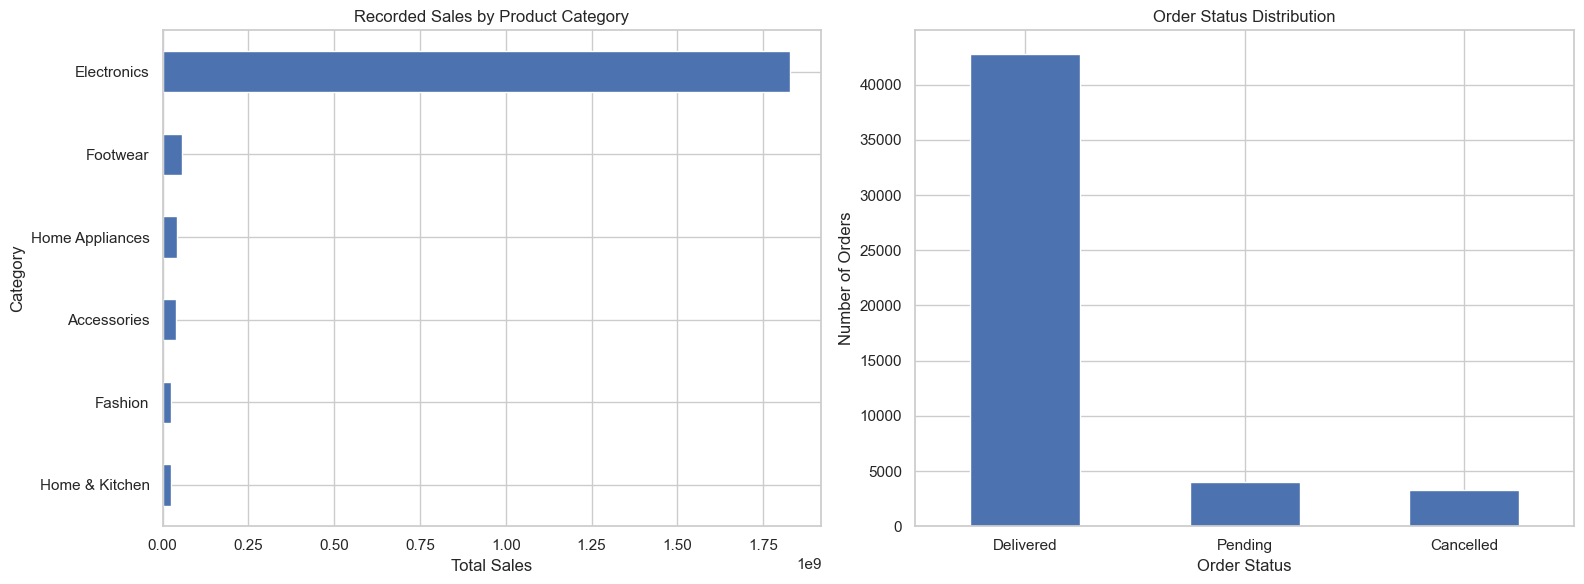

In [14]:

# STEP 14: SALES VISUALIZATION

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: Sales by category
category_sales["Total_Sales"].sort_values().plot(
    kind="barh",
    ax=axes[0]
)
axes[0].set_title("Recorded Sales by Product Category")
axes[0].set_xlabel("Total Sales")
axes[0].set_ylabel("Category")

# Chart 2: Order status distribution
status_counts = df["Order_Status"].value_counts()

status_counts.plot(
    kind="bar",
    ax=axes[1]
)
axes[1].set_title("Order Status Distribution")
axes[1].set_xlabel("Order Status")
axes[1].set_ylabel("Number of Orders")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


,Total_Sales,Total_Units,Order_Count
Date,,,
2026-01,"222,023,018.93",10839,5694
2026-02,"200,466,557.66",9592,5010
2026-03,"227,812,357.70",11049,5722
2026-04,"214,533,604.57",10589,5472
2026-05,"228,938,859.71",10785,5636
2026-06,"228,772,039.52",10734,5588
2026-07,"240,819,210.45",11018,5692
2026-08,"230,261,186.39",11048,5730
2026-09,"224,402,532.29",10558,5456


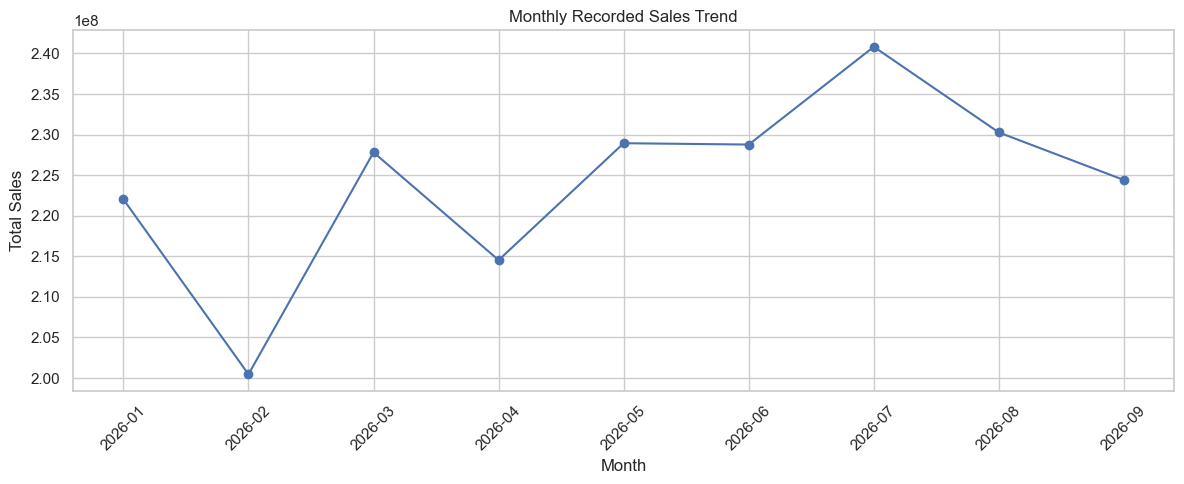

In [15]:

# STEP 15: MONTHLY SALES TREND

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

monthly_sales = (
    df.groupby(df["Date"].dt.to_period("M"))
    .agg(
        Total_Sales=("Total_Sales", "sum"),
        Total_Units=("Quantity", "sum"),
        Order_Count=("Order_ID", "nunique")
    )
)

monthly_sales.index = monthly_sales.index.astype(str)

display(monthly_sales)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales.index,
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title("Monthly Recorded Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [16]:

# STEP 16: BUSINESS LOGIC VALIDATION

# 1. Check whether Total_Sales matches Sale_Price × Quantity
df["Calculated_Sales"] = df["Sale_Price"] * df["Quantity"]

df["Sales_Difference"] = (
    df["Total_Sales"] - df["Calculated_Sales"]
).abs()

print("Sales calculation differences:")
print(df["Sales_Difference"].describe())

print(
    "\nRows with sales calculation mismatch:",
    (df["Sales_Difference"] > 0.01).sum()
)

# 2. Check invalid numerical values
print("\nInvalid price values:", (df["Price"] <= 0).sum())
print("Invalid sale prices:", (df["Sale_Price"] <= 0).sum())
print("Invalid quantities:", (df["Quantity"] <= 0).sum())
print("Negative recorded sales:", (df["Total_Sales"] < 0).sum())

# 3. Check discount percentage range
print(
    "\nDiscount percentage range:",
    df["Discount_Percentage"].min(),
    "to",
    df["Discount_Percentage"].max()
)

# 4. Inspect the order status and missing-value relationship
print("\nMissing values by order status:")
display(
    df.groupby("Order_Status")
    .agg(
        Order_Count=("Order_ID", "nunique"),
        Missing_Delivery_Days=("Delivery_Days", lambda x: x.isna().sum()),
        Missing_Customer_Rating=("Customer_Rating", lambda x: x.isna().sum())
    )
)


Sales calculation differences:
count   50,000.00
mean         0.00
std          0.00
min          0.00
25%          0.00
50%          0.00
75%          0.00
max          0.00
Name: Sales_Difference, dtype: float64

Rows with sales calculation mismatch: 0

Invalid price values: 0
Invalid sale prices: 0
Invalid quantities: 0
Negative recorded sales: 0

Discount percentage range: 0.0 to 27.66

Missing values by order status:


,Order_Count,Missing_Delivery_Days,Missing_Customer_Rating
Order_Status,,,
Cancelled,3240,3240,3240
Delivered,42777,0,0
Pending,3983,3983,3983


In [17]:

# ============================================
# PHASE 2: DATA PREPROCESSING
# STEP 19: CREATE WORKING COPY
# ============================================

df_clean = df.copy()

# Remove temporary validation columns if present
df_clean.drop(
    columns=["Calculated_Sales", "Sales_Difference"],
    errors="ignore",
    inplace=True
)

print("Working copy created successfully!")
print("Raw dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

display(df_clean.head())


Working copy created successfully!
Raw dataset shape: (50000, 22)
Working dataset shape: (50000, 20)


,Order_ID,Date,Product,Category,Price,Discount_Percentage,Sale_Price,Quantity,Total_Sales,Customer_ID,Customer_Name,Customer_Location,Payment_Method,Order_Status,Day_of_Week,Month,Order_Hour,Delivery_Days,Customer_Rating,Return_Flag
0,ORD000001,2026-09-22,boAt Airdopes 141,Electronics,"1,499.00",7.84,"1,381.48",2,"2,762.96",CUST26638,Customer_26638,Pune,UPI,Delivered,Tuesday,Sep,8,2.00,5.00,No
1,ORD000002,2026-01-24,Cello Lunch Box,Home & Kitchen,799.00,14.60,682.35,3,"2,047.05",CUST23013,Customer_23013,Coimbatore,EMI,Delivered,Saturday,Jan,17,7.00,3.70,No
2,ORD000003,2026-08-06,American Tourister Bag,Accessories,"3,999.00",8.06,"3,676.68",1,"3,676.68",CUST12070,Customer_12070,Hyderabad,UPI,Delivered,Thursday,Aug,14,6.00,4.50,No
3,ORD000004,2026-03-06,Levi's Jeans,Fashion,"2,999.00",6.26,"2,811.26",1,"2,811.26",CUST27880,Customer_27880,Hyderabad,UPI,Delivered,Friday,Mar,10,5.00,3.60,No
4,ORD000005,2026-08-03,OnePlus 12,Electronics,"59,999.00",3.98,"57,611.04",1,"57,611.04",CUST11552,Customer_11552,Jaipur,EMI,Delivered,Monday,Aug,15,5.00,4.40,No


In [18]:

# STEP 20: STANDARDIZE COLUMN NAMES

df_clean.columns = (
    df_clean.columns
    .str.strip()
)

# Convert date column
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    errors="coerce"
)

# Standardize categorical text
categorical_columns = [
    "Category",
    "Product",
    "Customer_Location",
    "Payment_Method",
    "Order_Status"
]

for col in categorical_columns:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
    )

print("Column and data type processing completed.")

display(
    df_clean[[
        "Date",
        "Category",
        "Product",
        "Price",
        "Sale_Price",
        "Quantity",
        "Total_Sales",
        "Order_Status"
    ]].dtypes.to_frame("Data_Type")
)


Column and data type processing completed.


,Data_Type
Date,datetime64[ns]
Category,string[python]
Product,string[python]
Price,float64
Sale_Price,float64
Quantity,int64
Total_Sales,float64
Order_Status,string[python]


In [19]:

# STEP 21: POST-CLEANING VALIDATION

print("Total rows:", len(df_clean))
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate order IDs:", df_clean["Order_ID"].duplicated().sum())
print("Invalid dates:", df_clean["Date"].isna().sum())

print("\nOrder status values:")
print(df_clean["Order_Status"].value_counts(dropna=False))

print("\nMissing values:")
display(
    df_clean.isna().sum()
    .to_frame("Missing_Count")
    .query("Missing_Count > 0")
)


Total rows: 50000
Duplicate rows: 0
Duplicate order IDs: 0
Invalid dates: 0

Order status values:
Order_Status
Delivered    42777
Pending       3983
Cancelled     3240
Name: count, dtype: Int64

Missing values:


,Missing_Count
Delivery_Days,7223
Customer_Rating,7223


In [20]:

# STEP 22: CREATE PRODUCT-LEVEL DEMAND DATA

# Exclude cancelled orders from the initial demand target.
# Pending orders are retained as recorded customer demand.
demand_source = df_clean.loc[
    df_clean["Order_Status"].isin(["Delivered", "Pending"])
].copy()

# Aggregate quantities by date and product
daily_demand = (
    demand_source.groupby(["Date", "Product"], as_index=False)
    .agg(
        Units_Sold=("Quantity", "sum"),
        Order_Count=("Order_ID", "nunique"),
        Recorded_Sales=("Total_Sales", "sum")
    )
    .sort_values(["Product", "Date"])
    .reset_index(drop=True)
)

print("Demand dataset shape:", daily_demand.shape)
print("Products:", daily_demand["Product"].nunique())
print("Date range:", daily_demand["Date"].min(), "to",
      daily_demand["Date"].max())

display(daily_demand.head(10))


Demand dataset shape: (6520, 5)
Products: 24
Date range: 2026-01-01 00:00:00 to 2026-09-30 00:00:00


,Date,Product,Units_Sold,Order_Count,Recorded_Sales
0,2026-01-01,Adidas Sports Shoes,20,10,"99,335.58"
1,2026-01-02,Adidas Sports Shoes,17,9,"85,905.40"
2,2026-01-03,Adidas Sports Shoes,23,11,"115,831.47"
3,2026-01-04,Adidas Sports Shoes,26,14,"127,596.56"
4,2026-01-05,Adidas Sports Shoes,7,5,"36,142.17"
5,2026-01-06,Adidas Sports Shoes,12,7,"61,025.71"
6,2026-01-07,Adidas Sports Shoes,18,10,"91,409.34"
7,2026-01-08,Adidas Sports Shoes,8,3,"41,972.20"
8,2026-01-09,Adidas Sports Shoes,7,4,"34,464.99"
9,2026-01-10,Adidas Sports Shoes,25,13,"126,877.30"


In [21]:

# STEP 23: CHECK DAILY DATA COVERAGE

start_date = daily_demand["Date"].min()
end_date = daily_demand["Date"].max()

expected_dates = pd.date_range(
    start=start_date,
    end=end_date,
    freq="D"
)

products = daily_demand["Product"].unique()

expected_rows = len(expected_dates) * len(products)
actual_rows = len(daily_demand)

print("Expected product-date combinations:", expected_rows)
print("Actual product-date combinations:", actual_rows)
print("Missing combinations:", expected_rows - actual_rows)

# Check duplicate product-date records
print(
    "Duplicate product-date combinations:",
    daily_demand.duplicated(["Date", "Product"]).sum()
)

# Find missing dates for each product
complete_index = pd.MultiIndex.from_product(
    [products, expected_dates],
    names=["Product", "Date"]
)

existing_index = pd.MultiIndex.from_frame(
    daily_demand[["Product", "Date"]]
)

missing_combinations = complete_index.difference(existing_index)

print("\nMissing combinations by product:")
print(
    pd.Series(
        [product for product, date in missing_combinations]
    ).value_counts()
)


Expected product-date combinations: 6552
Actual product-date combinations: 6520
Missing combinations: 32
Duplicate product-date combinations: 0

Missing combinations by product:
Titan Watch               11
American Tourister Bag     7
Philips Air Fryer          4
Fastrack Watch             2
Butterfly Gas Stove        2
Prestige Mixer Grinder     2
Prestige Cookware Set      2
Allen Solly Shirt          1
Wildcraft Backpack         1
Name: count, dtype: int64


In [22]:

# STEP 24: BUILD COMPLETE PRODUCT-LEVEL TIMELINE

daily_demand_complete = (
    daily_demand
    .set_index(["Product", "Date"])
    .reindex(complete_index)
    .reset_index()
)

# Fill only fields that represent recorded activity.
# This assumes a missing product-date means zero orders.
activity_columns = [
    "Units_Sold",
    "Order_Count",
    "Recorded_Sales"
]

daily_demand_complete[activity_columns] = (
    daily_demand_complete[activity_columns].fillna(0)
)

daily_demand_complete = daily_demand_complete.sort_values(
    ["Product", "Date"]
).reset_index(drop=True)

print("Complete dataset shape:", daily_demand_complete.shape)
print(
    "Remaining missing values:",
    daily_demand_complete.isna().sum().sum()
)

display(
    daily_demand_complete[
        daily_demand_complete["Units_Sold"] == 0
    ].head(10)
)


Complete dataset shape: (6552, 5)
Remaining missing values: 0


,Product,Date,Units_Sold,Order_Count,Recorded_Sales
544,Allen Solly Shirt,2026-09-29,0.00,0.00,0.00
562,American Tourister Bag,2026-01-17,0.00,0.00,0.00
605,American Tourister Bag,2026-03-01,0.00,0.00,0.00
610,American Tourister Bag,2026-03-06,0.00,0.00,0.00
611,American Tourister Bag,2026-03-07,0.00,0.00,0.00
661,American Tourister Bag,2026-04-26,0.00,0.00,0.00
751,American Tourister Bag,2026-07-25,0.00,0.00,0.00
779,American Tourister Bag,2026-08-22,0.00,0.00,0.00
1133,Butterfly Gas Stove,2026-02-11,0.00,0.00,0.00
1255,Butterfly Gas Stove,2026-06-13,0.00,0.00,0.00


In [23]:

# STEP 26: TIME-SERIES FEATURE ENGINEERING

feature_df = daily_demand_complete.copy()

feature_df["Date"] = pd.to_datetime(feature_df["Date"])

# Calendar features
feature_df["Day_Of_Week"] = feature_df["Date"].dt.dayofweek
feature_df["Day_Of_Month"] = feature_df["Date"].dt.day
feature_df["Month"] = feature_df["Date"].dt.month
feature_df["Is_Weekend"] = (
    feature_df["Day_Of_Week"] >= 5
).astype(int)

# Sort before creating lag features
feature_df = feature_df.sort_values(
    ["Product", "Date"]
).reset_index(drop=True)

# Previous observed demand
feature_df["Lag_1"] = (
    feature_df.groupby("Product")["Units_Sold"].shift(1)
)

feature_df["Lag_7"] = (
    feature_df.groupby("Product")["Units_Sold"].shift(7)
)

feature_df["Lag_14"] = (
    feature_df.groupby("Product")["Units_Sold"].shift(14)
)

# Previous 7-day average, excluding the current day
feature_df["Rolling_Mean_7"] = (
    feature_df.groupby("Product")["Units_Sold"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=7,
            min_periods=7
        ).mean()
    )
)

print("Feature engineering completed!")
print("Dataset shape:", feature_df.shape)

display(feature_df.head(20))


Feature engineering completed!
Dataset shape: (6552, 13)


,Product,Date,Units_Sold,Order_Count,Recorded_Sales,Day_Of_Week,Day_Of_Month,Month,Is_Weekend,Lag_1,Lag_7,Lag_14,Rolling_Mean_7
0,Adidas Sports Shoes,2026-01-01,20.00,10.00,"99,335.58",3,1,1,0,NaN,NaN,NaN,NaN
1,Adidas Sports Shoes,2026-01-02,17.00,9.00,"85,905.40",4,2,1,0,20.00,NaN,NaN,NaN
2,Adidas Sports Shoes,2026-01-03,23.00,11.00,"115,831.47",5,3,1,1,17.00,NaN,NaN,NaN
3,Adidas Sports Shoes,2026-01-04,26.00,14.00,"127,596.56",6,4,1,1,23.00,NaN,NaN,NaN
4,Adidas Sports Shoes,2026-01-05,7.00,5.00,"36,142.17",0,5,1,0,26.00,NaN,NaN,NaN
5,Adidas Sports Shoes,2026-01-06,12.00,7.00,"61,025.71",1,6,1,0,7.00,NaN,NaN,NaN
6,Adidas Sports Shoes,2026-01-07,18.00,10.00,"91,409.34",2,7,1,0,12.00,NaN,NaN,NaN
7,Adidas Sports Shoes,2026-01-08,8.00,3.00,"41,972.20",3,8,1,0,18.00,20.00,NaN,17.57
8,Adidas Sports Shoes,2026-01-09,7.00,4.00,"34,464.99",4,9,1,0,8.00,17.00,NaN,15.86
9,Adidas Sports Shoes,2026-01-10,25.00,13.00,"126,877.30",5,10,1,1,7.00,23.00,NaN,14.43


In [24]:

# STEP 27: CHECK FEATURE QUALITY

print("Missing values in engineered features:")
display(
    feature_df.isnull().sum()
    .to_frame("Missing_Count")
    .query("Missing_Count > 0")
)

print("\nDate coverage per product:")
display(
    feature_df.groupby("Product")["Date"]
    .agg(["min", "max", "count"])
)

print("\nDemand statistics:")
display(feature_df["Units_Sold"].describe())


Missing values in engineered features:


,Missing_Count
Lag_1,24
Lag_7,168
Lag_14,336
Rolling_Mean_7,168



Date coverage per product:


,min,max,count
Product,,,
Adidas Sports Shoes,2026-01-01,2026-09-30,273
Allen Solly Shirt,2026-01-01,2026-09-30,273
American Tourister Bag,2026-01-01,2026-09-30,273
Apple iPhone 15,2026-01-01,2026-09-30,273
Butterfly Gas Stove,2026-01-01,2026-09-30,273
Cello Lunch Box,2026-01-01,2026-09-30,273
Dell Inspiron Laptop,2026-01-01,2026-09-30,273
Fastrack Watch,2026-01-01,2026-09-30,273
HP Pavilion Laptop,2026-01-01,2026-09-30,273



Demand statistics:


count   6,552.00
mean       13.70
std         7.66
min         0.00
25%         8.00
50%        13.00
75%        18.00
max        54.00
Name: Units_Sold, dtype: float64

In [25]:

# STEP 28: PREPARE SUPERVISED ML DATASET

model_df = feature_df.dropna(
    subset=[
        "Lag_1",
        "Lag_7",
        "Lag_14",
        "Rolling_Mean_7"
    ]
).copy()

model_df = model_df.sort_values(
    ["Date", "Product"]
).reset_index(drop=True)

print("Original complete records:", len(feature_df))
print("Records available for modeling:", len(model_df))
print("Missing values in model dataset:", model_df.isna().sum().sum())

display(model_df.head())


Original complete records: 6552
Records available for modeling: 6216
Missing values in model dataset: 0


,Product,Date,Units_Sold,Order_Count,Recorded_Sales,Day_Of_Week,Day_Of_Month,Month,Is_Weekend,Lag_1,Lag_7,Lag_14,Rolling_Mean_7
0,Adidas Sports Shoes,2026-01-15,12.00,7.00,"62,315.20",3,15,1,0,23.00,8.00,20.00,15.43
1,Allen Solly Shirt,2026-01-15,7.00,5.00,"16,082.82",3,15,1,0,2.00,15.00,12.00,11.57
2,American Tourister Bag,2026-01-15,2.00,1.00,"7,414.14",3,15,1,0,14.00,10.00,4.00,9.86
3,Apple iPhone 15,2026-01-15,27.00,14.00,"1,730,403.29",3,15,1,0,22.00,29.00,18.00,20.29
4,Butterfly Gas Stove,2026-01-15,3.00,2.00,"11,762.26",3,15,1,0,14.00,12.00,4.00,11.71


In [26]:

# STEP 29: CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT

test_start = pd.Timestamp("2026-09-01")
validation_start = pd.Timestamp("2026-08-02")

train_df = model_df[
    model_df["Date"] < validation_start
].copy()

validation_df = model_df[
    (model_df["Date"] >= validation_start) &
    (model_df["Date"] < test_start)
].copy()

test_df = model_df[
    model_df["Date"] >= test_start
].copy()

print("Training period:")
print(train_df["Date"].min(), "to", train_df["Date"].max())
print("Training rows:", len(train_df))

print("\nValidation period:")
print(validation_df["Date"].min(), "to", validation_df["Date"].max())
print("Validation rows:", len(validation_df))

print("\nTest period:")
print(test_df["Date"].min(), "to", test_df["Date"].max())
print("Test rows:", len(test_df))


Training period:
2026-01-15 00:00:00 to 2026-08-01 00:00:00
Training rows: 4776

Validation period:
2026-08-02 00:00:00 to 2026-08-31 00:00:00
Validation rows: 720

Test period:
2026-09-01 00:00:00 to 2026-09-30 00:00:00
Test rows: 720


In [27]:

# STEP 31: IMPORT MACHINE LEARNING LIBRARIES

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Machine learning libraries imported successfully!")


Machine learning libraries imported successfully!


In [28]:

# STEP 32: DEFINE INPUT FEATURES AND TARGET

TARGET = "Units_Sold"

NUMERIC_FEATURES = [
    "Day_Of_Week",
    "Day_Of_Month",
    "Month",
    "Is_Weekend",
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "Rolling_Mean_7"
]

CATEGORICAL_FEATURES = ["Product"]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_val = validation_df[FEATURES]
y_val = validation_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print("Features:", FEATURES)
print("Target:", TARGET)
print("Training input shape:", X_train.shape)
print("Validation input shape:", X_val.shape)
print("Test input shape:", X_test.shape)


Features: ['Day_Of_Week', 'Day_Of_Month', 'Month', 'Is_Weekend', 'Lag_1', 'Lag_7', 'Lag_14', 'Rolling_Mean_7', 'Product']
Target: Units_Sold
Training input shape: (4776, 9)
Validation input shape: (720, 9)
Test input shape: (720, 9)


In [29]:

# STEP 33: SEASONAL NAIVE BASELINE

baseline_val_predictions = validation_df["Lag_7"].to_numpy()

baseline_mae = mean_absolute_error(
    y_val,
    baseline_val_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_val, baseline_val_predictions)
)

baseline_wape = (
    np.abs(y_val.to_numpy() - baseline_val_predictions).sum()
    / max(np.abs(y_val.to_numpy()).sum(), 1e-10)
) * 100

print("SEASONAL BASELINE — VALIDATION")
print(f"MAE:   {baseline_mae:.4f}")
print(f"RMSE:  {baseline_rmse:.4f}")
print(f"WAPE:  {baseline_wape:.2f}%")


SEASONAL BASELINE — VALIDATION
MAE:   6.4917
RMSE:  8.2723
WAPE:  46.77%


In [30]:

# STEP 34: CREATE PREPROCESSING PIPELINE

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, NUMERIC_FEATURES),
        ("cat", categorical_transformer, CATEGORICAL_FEATURES)
    ]
)

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully!")


Random Forest pipeline created successfully!


In [31]:

# STEP 35: TRAIN RANDOM FOREST

rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully!")


Random Forest training completed successfully!


In [32]:

# STEP 36: VALIDATION EVALUATION

rf_val_predictions = np.maximum(
    rf_model.predict(X_val),
    0
)

rf_mae = mean_absolute_error(
    y_val,
    rf_val_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_val, rf_val_predictions)
)

rf_wape = (
    np.abs(y_val.to_numpy() - rf_val_predictions).sum()
    / max(np.abs(y_val.to_numpy()).sum(), 1e-10)
) * 100

comparison = pd.DataFrame({
    "Model": ["Seasonal Baseline", "Random Forest"],
    "MAE": [baseline_mae, rf_mae],
    "RMSE": [baseline_rmse, rf_rmse],
    "WAPE_Percent": [baseline_wape, rf_wape]
})

display(comparison.round(3))


,Model,MAE,RMSE,WAPE_Percent
0,Seasonal Baseline,6.49,8.27,46.77
1,Random Forest,4.96,6.17,35.74


In [33]:

# STEP 38: FINAL TEST EVALUATION

# Seasonal baseline on unseen test data
baseline_test_predictions = test_df["Lag_7"].to_numpy()

# Random Forest predictions
rf_test_predictions = np.maximum(
    rf_model.predict(X_test),
    0
)

def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    wape = (
        np.abs(y_true - y_pred).sum()
        / max(np.abs(y_true).sum(), 1e-10)
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE_Percent": wape
    }

test_comparison = pd.DataFrame([
    {
        "Model": "Seasonal Baseline",
        **calculate_metrics(
            y_test, baseline_test_predictions
        )
    },
    {
        "Model": "Random Forest",
        **calculate_metrics(
            y_test, rf_test_predictions
        )
    }
])

display(test_comparison.round(3))


,Model,MAE,RMSE,WAPE_Percent
0,Seasonal Baseline,6.61,8.43,48.25
1,Random Forest,4.92,6.26,35.86


,Date,Product,Units_Sold,Baseline_Prediction,RF_Prediction,Absolute_Error
5496,2026-09-01,Adidas Sports Shoes,12.00,11.00,12.21,0.21
5497,2026-09-01,Allen Solly Shirt,13.00,9.00,12.24,0.76
5498,2026-09-01,American Tourister Bag,4.00,3.00,7.42,3.42
5499,2026-09-01,Apple iPhone 15,21.00,32.00,26.61,5.61
5500,2026-09-01,Butterfly Gas Stove,6.00,4.00,8.43,2.43
5501,2026-09-01,Cello Lunch Box,20.00,23.00,15.78,4.22
5502,2026-09-01,Dell Inspiron Laptop,10.00,17.00,13.01,3.01
5503,2026-09-01,Fastrack Watch,9.00,22.00,10.93,1.93
5504,2026-09-01,HP Pavilion Laptop,9.00,13.00,13.25,4.25
5505,2026-09-01,Levi's Jeans,10.00,19.00,14.30,4.30


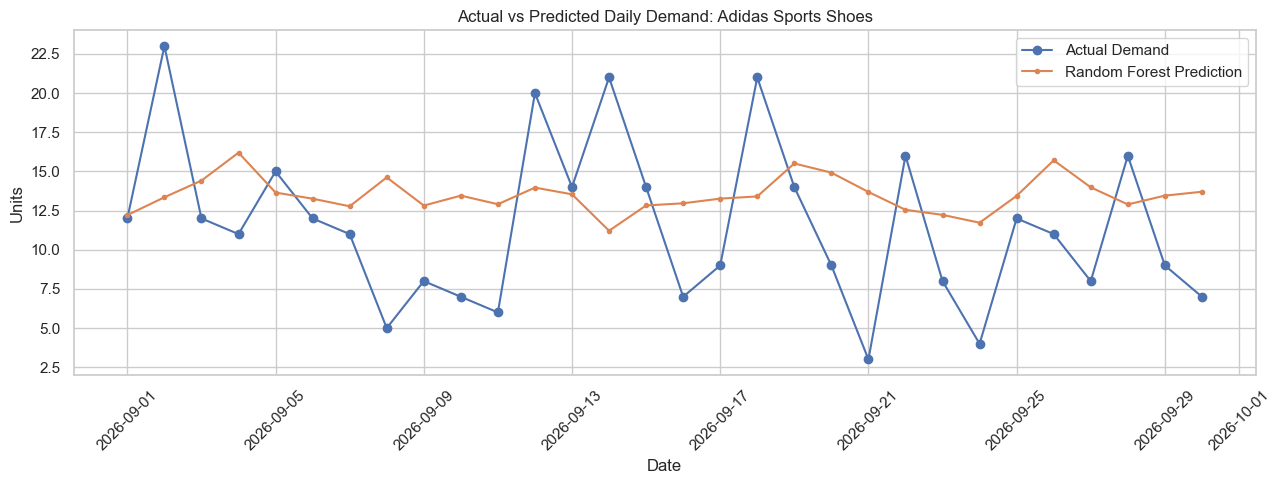

In [34]:

# STEP 39: ACTUAL VS PREDICTED DEMAND

results_df = test_df[
    ["Date", "Product", "Units_Sold"]
].copy()

results_df["Baseline_Prediction"] = baseline_test_predictions
results_df["RF_Prediction"] = rf_test_predictions

results_df["Absolute_Error"] = np.abs(
    results_df["Units_Sold"] - results_df["RF_Prediction"]
)

display(results_df.head(20))

# Visualize one product across September
sample_product = results_df["Product"].iloc[0]

product_results = (
    results_df[results_df["Product"] == sample_product]
    .sort_values("Date")
)

plt.figure(figsize=(13, 5))

plt.plot(
    product_results["Date"],
    product_results["Units_Sold"],
    marker="o",
    label="Actual Demand"
)

plt.plot(
    product_results["Date"],
    product_results["RF_Prediction"],
    marker=".",
    label="Random Forest Prediction"
)

plt.title(f"Actual vs Predicted Daily Demand: {sample_product}")
plt.xlabel("Date")
plt.ylabel("Units")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [35]:

# STEP 40: SAVE THE TRAINED PIPELINE

import joblib

model_dir = PROJECT_DIR / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "amazon_demand_notebook_experiment.joblib"

joblib.dump(rf_model, model_path)

print("Model saved successfully:", model_path)


Model saved successfully: models/amazon_demand_notebook_experiment.joblib


In [36]:

# STEP 41: FINAL TEST PERFORMANCE

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Generate predictions
rf_test_predictions = np.maximum(
    rf_model.predict(X_test), 0
)

baseline_test_predictions = test_df["Lag_7"].to_numpy()

# Calculate metrics
def evaluate_model(y_true, predictions):
    return {
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, predictions)
        ),
        "WAPE (%)": (
            np.abs(np.asarray(y_true) - predictions).sum()
            / max(np.abs(np.asarray(y_true)).sum(), 1e-10)
        ) * 100
    }

test_results = pd.DataFrame([
    {
        "Model": "Seasonal Baseline",
        **evaluate_model(y_test, baseline_test_predictions)
    },
    {
        "Model": "Random Forest",
        **evaluate_model(y_test, rf_test_predictions)
    }
])

display(test_results.round(3))


,Model,MAE,RMSE,WAPE (%)
0,Seasonal Baseline,6.61,8.43,48.25
1,Random Forest,4.92,6.26,35.86


In [37]:

# STEP 42: FINAL TEST METRICS

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Generate predictions
rf_test_predictions = np.maximum(rf_model.predict(X_test), 0)
baseline_test_predictions = test_df["Lag_7"].to_numpy()

def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "WAPE (%)": (
            np.abs(y_true - y_pred).sum()
            / max(np.abs(y_true).sum(), 1e-10)
        ) * 100
    }

test_results = pd.DataFrame([
    {"Model": "Seasonal Baseline",
     **evaluate(y_test, baseline_test_predictions)},
    {"Model": "Random Forest",
     **evaluate(y_test, rf_test_predictions)}
])

display(test_results.round(3))


,Model,MAE,RMSE,WAPE (%)
0,Seasonal Baseline,6.61,8.43,48.25
1,Random Forest,4.92,6.26,35.86
